# P7.9 — Filtro passa-faixa FIR com janela de Hann

**Referência:** Ingle & Proakis, *DSP Using MATLAB*, 3ª ed., p. 378 · DTA §2.1 (item 1) e §4 (Resolução P7.9).

> *Design a linear-phase bandpass filter using the Hann window design technique. The specifications are: lower stopband edge: 0.2π, As = 40 dB; upper stopband edge: 0.75π; lower passband edge: 0.35π, Rp = 0.25 dB; upper passband edge: 0.55π. Plot the impulse response and the magnitude response (in dB) of the designed filter. Do not use the fir1 function.*

| Parâmetro | Valor |
|---|---|
| Rejeição inferior | $0 \le \omega \le 0.2\pi$ |
| Passagem | $0.35\pi \le \omega \le 0.55\pi$, $R_p = 0.25$ dB |
| Rejeição superior | $0.75\pi \le \omega \le \pi$, $A_s = 40$ dB |
| Método | janela de Hann (imposta), sem `fir1` |

In [1]:
# Configuração do ambiente (local ou Google Colab)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab, disponibilize o projeto em PROJECT_DIR antes de executar:
    #   (a) Arquivos → upload de dsp-avaliacao-2.zip e  !unzip -q dsp-avaliacao-2.zip
    #   (b) ou monte o Drive:  from google.colab import drive; drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/dsp-avaliacao-2")
    %pip install -q -r {PROJECT_DIR}/requirements.txt
else:
    PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

for p in (PROJECT_DIR, PROJECT_DIR / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("Projeto em:", PROJECT_DIR)

Projeto em: /mnt/storage/projects/dsp-avaliacao-2


## 1. Método

**Largura de transição.** As duas transições são diferentes:
$\Delta\omega_1 = 0.35\pi - 0.2\pi = 0.15\pi$ e $\Delta\omega_2 = 0.75\pi - 0.55\pi = 0.20\pi$.
O método da janela produz transições de mesma largura nos dois lados, então a mais estreita manda: $\Delta\omega = 0.15\pi$.

**Janela.** Pela Tabela 7.1, a Hann garante $A_s \approx 44$ dB $\ge 40$ dB e tem transição $\Delta\omega = 6.2\pi/M$:

$$M = \left\lceil \frac{6.2\pi}{0.15\pi} \right\rceil + 1 = \lceil 41.33 \rceil + 1 = 43 \quad\Rightarrow\quad \text{Tipo 1},\ \alpha = \frac{M-1}{2} = 21$$

$$w(n) = 0.5 - 0.5\cos\left(\frac{2\pi n}{M-1}\right), \quad 0 \le n \le M-1$$

**Cortes ideais** (meio das transições): $\omega_{c1} = \frac{0.2\pi + 0.35\pi}{2} = 0.275\pi$, $\omega_{c2} = \frac{0.55\pi + 0.75\pi}{2} = 0.65\pi$.

**Resposta ideal e janelamento:**

$$h_d(n) = \frac{\sin[\omega_{c2}(n-\alpha)] - \sin[\omega_{c1}(n-\alpha)]}{\pi(n-\alpha)}, \qquad h(n) = h_d(n)\,w(n)$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from dsp_av2.fir import analysis
from dsp_av2.specs import P7_9 as SPEC
from exercises import p7_09

d = p7_09.design()
print(f"Δω = {d.transition_width:g}π")
print(f"ωc1 = {d.cutoffs[0]:g}π, ωc2 = {d.cutoffs[1]:g}π")
print(f"M = {d.M}  (Tabela 7.1: {d.M_table}),  α = {d.alpha:g}")
print("Tipo de fase linear:", analysis.linear_phase_type(d.h))

Δω = 0.15π
ωc1 = 0.275π, ωc2 = 0.65π
M = 43  (Tabela 7.1: 43),  α = 21
Tipo de fase linear: 1


## 2. Resultados

Pedidos pelo enunciado: resposta ao impulso $h(n)$ e magnitude em dB. O terceiro painel (zoom na passagem) foi acrescentado para tornar visível a verificação de $R_p$.

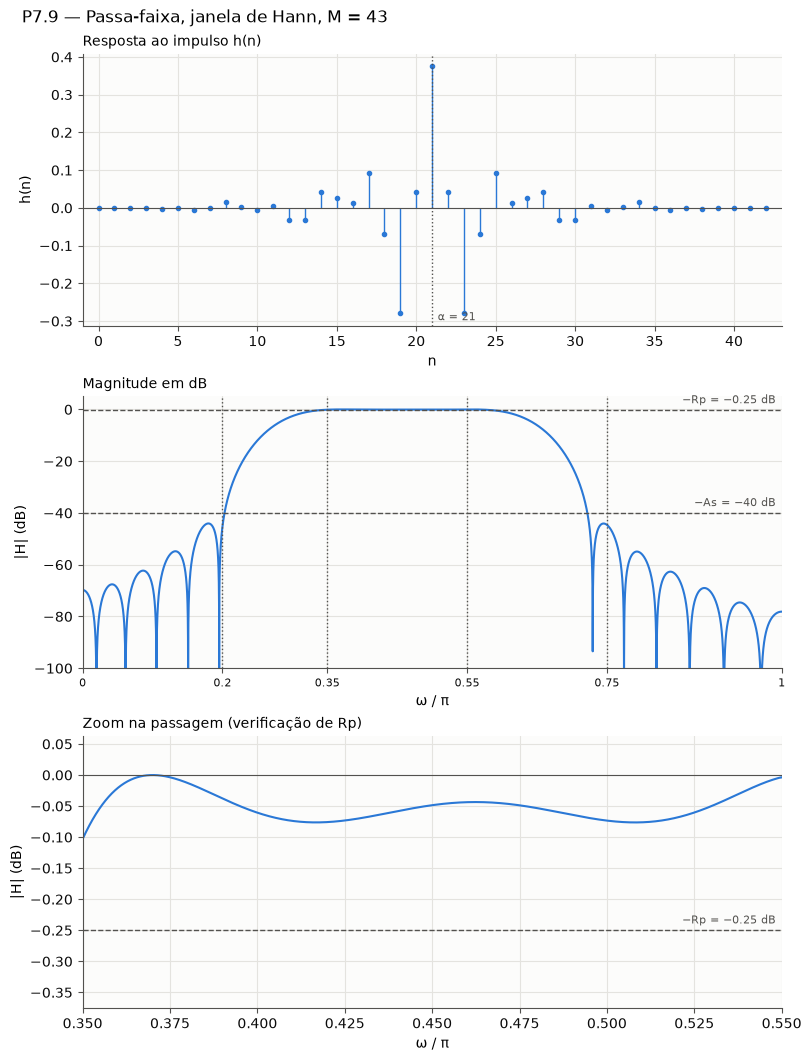

In [3]:
fig = p7_09.plot(d)
plt.show()

## 3. Validação contra a especificação

As medições seguem a convenção do livro (função `freqz_m`): magnitude em dB normalizada pelo máximo,
$R_p = -\min_{\text{passagem}} |H|_{dB}$ e $A_s = -\max_{\text{rejeição}} |H|_{dB}$.

As grades de frequência **incluem as bordas exatas** (0.2π, 0.35π, 0.55π, 0.75π). Uma grade que pula as bordas pode superestimar $A_s$ (ver `docs/plano_implementacao.md`, decisão D8).

In [4]:
report = p7_09.validate(d)
print(report)

Validação P7.9 (Tipo 1 de fase linear)
  [OK  ] Rp [dB] (grade livro): 0.1030 <= 0.2500  (folga +0.1470)
  [OK  ] As [dB] (grade livro): 44.0545 >= 40.0000  (folga +4.0545)
  [OK  ] Rp [dB] (grade densa): 0.1031 <= 0.2500  (folga +0.1469)
  [OK  ] As [dB] (grade densa): 44.0542 >= 40.0000  (folga +4.0542)
  Resultado: ATENDE à especificação


**Verificação independente.** `scipy.signal.firwin` (o equivalente ao `fir1`) é proibido na solução, mas pode servir de conferência. Com a mesma janela e sem normalização de ganho, ele deve reproduzir $h(n)$:

In [5]:
from scipy.signal import firwin
ref = firwin(d.M, list(d.cutoffs), window="hann", pass_zero=False, scale=False)
print("max |h − h_firwin| =", np.max(np.abs(d.h - ref)))

max |h − h_firwin| = 1.0061396160665481e-16


## 4. Conclusão

- Com a janela de Hann e $M = 43$ (Tipo 1, $\alpha = 21$), o filtro atende à especificação: $R_p \approx 0.10$ dB $\le 0.25$ dB e $A_s \approx 44.05$ dB $\ge 40$ dB.
- A atenuação medida coincide com o valor nominal da Tabela 7.1 (44 dB). A $A_s$ máxima alcançável é uma propriedade da janela (lóbulos laterais), e $M$ controla a largura da transição. Com $M$ suficiente para a transição caber entre as bordas, $A_s$ fica perto do valor da janela. Se $M$ for curto demais, a borda de rejeição cai dentro da transição e $A_s$ despenca.
- A $R_p$ fica bem abaixo do limite, pois a ondulação da passagem acompanha a da rejeição ($\delta_1 \approx \delta_2 \approx 0.006$).
- Valores do DTA: $A_s = 44.00$ dB e $R_p = 0.1019$ dB. As diferenças estão na terceira casa decimal e vêm da grade de avaliação.